<a href="https://colab.research.google.com/github/kunwar1908/Cognitive-Computing-UCS420/blob/main/Assignment10_Diabetes_Assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420: Cognitive Computing - Assignment 10
## Diabetes Care Information Assistant (Odd Roll Number Track)
---
This complete interactive Jupyter Notebook is tailored for **Odd Roll Numbers** (Diabetes Care Information Assistant).

### Assignment Checklist (10/10 Requirements):
1. **Labelled Corpus:** 50 labelled queries across 5 clinical diabetes intent categories.
2. **Hierarchical Taxonomy:** 4 major categories with 2+ subcategories each.
3. **Domain Concepts & Knowledge Graph:** 10 core diabetes concepts with 12 explicit semantic relations.
4. **NLP Preprocessing Pipeline:** Lowercase conversion, regex cleaning, tokenization, stopword removal, and WordNet lemmatization.
5. **Feature Extraction & Machine Learning:** TF-IDF n-gram vectorizer paired with a trained classifier (MultinomialNB / LogisticRegression).
6. **Model Evaluation:** Accuracy, Precision, Recall, F1-Score, Classification Report, and Confusion Matrix Heatmap.
7. **Domain Knowledge Base:** Comprehensive evidence-based diabetes knowledge repository (symptoms, diet/lifestyle, medication, monitoring, complications).
8. **Cognitive Rule Engine:** 5 explicit clinical rules (Emergency Escalation, Scope/Unsupported Filtering, Low-Confidence Fallback, Acute Hypoglycemia 15-15 Rule, and Gestational/Pediatric Referral).
9. **Unified Cognitive Assistant:** Seamless integration of NLP, ML classification, rule reasoning, and knowledge retrieval.
10. **Interactive Deployment & Validation Suite:** Comprehensive testing on all 5 prescribed edge-cases + interactive Colab input loop.

## Step 0: Environment Setup & Library Downloads

In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# Download NLTK linguistic datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

print("Environment initialized and NLTK resources ready.")

Environment initialized and NLTK resources ready.


---
## Requirement 1: Labelled Diabetes Corpus (50 Queries Across 5 Intents)
Corpus categories:
1. `symptom_inquiry`
2. `diet_lifestyle`
3. `medication_guidance`
4. `monitoring_diagnostics`
5. `complications_risks`

In [2]:
corpus_data = [
    # 1. symptom_inquiry
    ("What are the early warning signs of high blood sugar in type 2 diabetes?", "symptom_inquiry"),
    ("Why do I feel extreme thirst, dry mouth, and frequent urination at night?", "symptom_inquiry"),
    ("Are unexplained fatigue, blurry vision, and slow wound healing signs of diabetes?", "symptom_inquiry"),
    ("What causes sudden shakiness, cold sweating, and dizziness after skipping meals?", "symptom_inquiry"),
    ("Is persistent tingling or burning numbness in feet a symptom of diabetic neuropathy?", "symptom_inquiry"),
    ("How do I recognize when my blood glucose drops dangerously low below 70?", "symptom_inquiry"),
    ("Warning symptoms of unexplained rapid weight loss despite increased appetite and hunger.", "symptom_inquiry"),
    ("Why do I get dizzy spells, headache, and confusion in the middle of the night?", "symptom_inquiry"),
    ("What are the common signs of severe hyperglycemia and ketoacidosis?", "symptom_inquiry"),
    ("Is recurrent fungal skin infection or itching an indicator of high sugar levels?", "symptom_inquiry"),

    # 2. diet_lifestyle
    ("What foods should a diabetic eat to manage blood glucose and prevent spikes?", "diet_lifestyle"),
    ("Can a person with diabetes eat fruits like apples, berries, and bananas safely?", "diet_lifestyle"),
    ("What is the best low glycemic index diet plan for breakfast and lunch?", "diet_lifestyle"),
    ("How many minutes of brisk walking or aerobic exercise is recommended each week?", "diet_lifestyle"),
    ("Is intermittent fasting or a low-carb ketogenic diet safe for type 2 diabetes?", "diet_lifestyle"),
    ("Can switching from white rice to whole grains, millets, and oats reduce HbA1c?", "diet_lifestyle"),
    ("Which processed carbohydrates and sugar-sweetened beverages must be eliminated?", "diet_lifestyle"),
    ("How does a 15-minute post-meal walk reduce postprandial blood sugar spikes?", "diet_lifestyle"),
    ("What is the diabetes plate method for portion control and balanced nutrition?", "diet_lifestyle"),
    ("Best dietary habits to manage both elevated cholesterol and blood glucose together.", "diet_lifestyle"),

    # 3. medication_guidance
    ("When is the best time to take Metformin, before or after a meal?", "medication_guidance"),
    ("What should I do if I accidentally forget to take my scheduled insulin injection?", "medication_guidance"),
    ("What are the common gastrointestinal side effects of Metformin 500mg?", "medication_guidance"),
    ("How does long-acting basal insulin differ from rapid-acting bolus insulin?", "medication_guidance"),
    ("Can oral diabetes tablets like Glimepiride cause hypoglycemia if meals are delayed?", "medication_guidance"),
    ("Where should I store unopened insulin pens and vials safely in the refrigerator?", "medication_guidance"),
    ("How do SGLT2 inhibitors like Dapagliflozin help remove glucose through urine?", "medication_guidance"),
    ("Proper technique and site rotation for injecting insulin in the abdomen and thighs.", "medication_guidance"),
    ("Can diabetes medications be taken safely alongside blood pressure or statin pills?", "medication_guidance"),
    ("Should I adjust or skip my insulin dose when sick or during strenuous workouts?", "medication_guidance"),

    # 4. monitoring_diagnostics
    ("What is a normal fasting blood sugar and postprandial glucose reading?", "monitoring_diagnostics"),
    ("How often should a diabetic patient get an HbA1c test done at a diagnostic lab?", "monitoring_diagnostics"),
    ("What fasting blood glucose level confirms a diagnosis of prediabetes or diabetes?", "monitoring_diagnostics"),
    ("How do I use a continuous glucose monitor CGM sensor to track sugar trends?", "monitoring_diagnostics"),
    ("How to calibrate and check the accuracy of a home glucometer with test strips?", "monitoring_diagnostics"),
    ("What is the ideal target blood glucose range before going to bed at night?", "monitoring_diagnostics"),
    ("What do elevated urine ketone strip readings indicate during high blood sugar?", "monitoring_diagnostics"),
    ("When is the accurate time window to test post-meal sugar after finishing lunch?", "monitoring_diagnostics"),
    ("What does an oral glucose tolerance test OGTT tell us about insulin resistance?", "monitoring_diagnostics"),
    ("Understanding estimated average glucose eAG calculated from an HbA1c report.", "monitoring_diagnostics"),

    # 5. complications_risks
    ("How does long-term uncontrolled diabetes damage kidney nephrons and cause nephropathy?", "complications_risks"),
    ("What is diabetic retinopathy and how does high sugar cause retinal damage or blindness?", "complications_risks"),
    ("Why are foot ulcers and peripheral neuropathy dangerous in chronic diabetes?", "complications_risks"),
    ("How does elevated blood glucose increase the long-term risk of heart attack and stroke?", "complications_risks"),
    ("What causes diabetic gastroparesis and delayed stomach emptying in diabetic patients?", "complications_risks"),
    ("How does an annual urine microalbumin test help detect early diabetic kidney disease?", "complications_risks"),
    ("Why do diabetics suffer from poor peripheral vascular circulation and slow infection healing?", "complications_risks"),
    ("Daily diabetic foot inspection strategies to prevent blisters and amputation.", "complications_risks"),
    ("How does chronic hyperglycemia stiffen blood vessels and accelerate atherosclerosis?", "complications_risks"),
    ("What are the major long-term microvascular and macrovascular risks of diabetes?", "complications_risks")
]

df_corpus = pd.DataFrame(corpus_data, columns=["query", "intent"])
print(f"Total labelled queries: {len(df_corpus)}")
print("\nDistribution across intents:")
print(df_corpus["intent"].value_counts())

Total labelled queries: 50

Distribution across intents:
intent
symptom_inquiry           10
diet_lifestyle            10
medication_guidance       10
monitoring_diagnostics    10
complications_risks       10
Name: count, dtype: int64


---
## Requirement 2: Hierarchical Diabetes Taxonomy
Constructed with 4 major categories and at least 2 subcategories each.

In [3]:
diabetes_taxonomy = {
    "Glycemic Regulation & Metabolic States": {
        "Hyperglycemia": ["Elevated Fasting Plasma Glucose", "Postprandial Spikes", "Diabetic Ketoacidosis (DKA)"],
        "Hypoglycemia": ["Adrenergic Shakiness & Sweating", "Neuroglycopenia & Confusion", "Nocturnal Hypoglycemia"]
    },
    "Lifestyle Therapeutics & Nutrition": {
        "Medical Nutrition Therapy": ["Low-Glycemic Index Diet", "Complex Dietary Fiber", "Portion Control Plate Method"],
        "Physical Activity": ["Moderate Aerobic Exercise", "Resistance Training", "Post-Prandial Walking"]
    },
    "Pharmacotherapy & Clinical Therapeutics": {
        "Oral Hypoglycemic Agents": ["Biguanides (Metformin)", "Sulfonylureas (Glimepiride)", "SGLT2 Inhibitors"],
        "Insulin Regimens": ["Basal Long-Acting Insulin", "Bolus Rapid-Acting Insulin", "Cold-Chain Storage & Injection Sites"]
    },
    "Diabetic Vascular Complications": {
        "Microvascular Disorders": ["Diabetic Nephropathy (Kidneys)", "Diabetic Retinopathy (Eyes)", "Peripheral Neuropathy (Nerves)"],
        "Macrovascular Disorders": ["Coronary Artery Disease", "Atherosclerotic Stroke", "Peripheral Arterial Disease & Diabetic Foot"]
    }
}

print("=== Hierarchical Diabetes Care Taxonomy ===")
for category, subcats in diabetes_taxonomy.items():
    print(f"\n[Major Category] {category}")
    for subcat, items in subcats.items():
        print(f"   └── [Subcategory] {subcat}: {', '.join(items)}")

=== Hierarchical Diabetes Care Taxonomy ===

[Major Category] Glycemic Regulation & Metabolic States
   └── [Subcategory] Hyperglycemia: Elevated Fasting Plasma Glucose, Postprandial Spikes, Diabetic Ketoacidosis (DKA)
   └── [Subcategory] Hypoglycemia: Adrenergic Shakiness & Sweating, Neuroglycopenia & Confusion, Nocturnal Hypoglycemia

[Major Category] Lifestyle Therapeutics & Nutrition
   └── [Subcategory] Medical Nutrition Therapy: Low-Glycemic Index Diet, Complex Dietary Fiber, Portion Control Plate Method
   └── [Subcategory] Physical Activity: Moderate Aerobic Exercise, Resistance Training, Post-Prandial Walking

[Major Category] Pharmacotherapy & Clinical Therapeutics
   └── [Subcategory] Oral Hypoglycemic Agents: Biguanides (Metformin), Sulfonylureas (Glimepiride), SGLT2 Inhibitors
   └── [Subcategory] Insulin Regimens: Basal Long-Acting Insulin, Bolus Rapid-Acting Insulin, Cold-Chain Storage & Injection Sites

[Major Category] Diabetic Vascular Complications
   └── [Subcatego

---
## Requirement 3: Domain Concepts & Semantic Relationship Graph
10 domain concepts interconnected via 12 explicit semantic relations.

In [4]:
diabetes_concepts = [
    "Insulin", "Blood Glucose", "Pancreatic Beta Cells", "Metformin",
    "HbA1c", "Diabetic Nephropathy", "Diabetic Neuropathy",
    "Carbohydrates", "Aerobic Exercise", "Cardiovascular Disease"
]

semantic_relationships = [
    ("Pancreatic Beta Cells", "secretes", "Insulin"),
    ("Insulin", "regulates_and_lowers", "Blood Glucose"),
    ("Carbohydrates", "metabolizes_into", "Blood Glucose"),
    ("Metformin", "improves_sensitivity_to", "Insulin"),
    ("Metformin", "inhibits_hepatic_production_of", "Blood Glucose"),
    ("Blood Glucose", "glycates_hemoglobin_forming", "HbA1c"),
    ("HbA1c", "serves_as_clinical_biomarker_for", "Blood Glucose"),
    ("Chronic High Blood Glucose", "causes_microvascular_damage_to", "Diabetic Nephropathy"),
    ("Chronic High Blood Glucose", "causes_peripheral_nerve_degeneration_in", "Diabetic Neuropathy"),
    ("Chronic High Blood Glucose", "accelerates_atherosclerosis_causing", "Cardiovascular Disease"),
    ("Aerobic Exercise", "stimulates_insulin_independent_uptake_of", "Blood Glucose"),
    ("Aerobic Exercise", "reduces_systemic_risk_of", "Cardiovascular Disease")
]

print(f"Identified Diabetes Domain Concepts ({len(diabetes_concepts)}):")
for c in diabetes_concepts:
    print(f" • {c}")

print(f"\nDefined Semantic Knowledge Graph Relationships ({len(semantic_relationships)}):")
for s, r, o in semantic_relationships:
    print(f" • ({s}) ─── [{r}] ───> ({o})")

Identified Diabetes Domain Concepts (10):
 • Insulin
 • Blood Glucose
 • Pancreatic Beta Cells
 • Metformin
 • HbA1c
 • Diabetic Nephropathy
 • Diabetic Neuropathy
 • Carbohydrates
 • Aerobic Exercise
 • Cardiovascular Disease

Defined Semantic Knowledge Graph Relationships (12):
 • (Pancreatic Beta Cells) ─── [secretes] ───> (Insulin)
 • (Insulin) ─── [regulates_and_lowers] ───> (Blood Glucose)
 • (Carbohydrates) ─── [metabolizes_into] ───> (Blood Glucose)
 • (Metformin) ─── [improves_sensitivity_to] ───> (Insulin)
 • (Metformin) ─── [inhibits_hepatic_production_of] ───> (Blood Glucose)
 • (Blood Glucose) ─── [glycates_hemoglobin_forming] ───> (HbA1c)
 • (HbA1c) ─── [serves_as_clinical_biomarker_for] ───> (Blood Glucose)
 • (Chronic High Blood Glucose) ─── [causes_microvascular_damage_to] ───> (Diabetic Nephropathy)
 • (Chronic High Blood Glucose) ─── [causes_peripheral_nerve_degeneration_in] ───> (Diabetic Neuropathy)
 • (Chronic High Blood Glucose) ─── [accelerates_atherosclerosis_c

---
## Requirement 4: NLP Preprocessing Pipeline
Text processing pipeline implementing:
- Lowercase conversion
- Regex punctuation removal
- Tokenization (`nltk.word_tokenize`)
- Stopword removal (`nltk.corpus.stopwords`)
- Lemmatization (`nltk.stem.WordNetLemmatizer`)

In [5]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # 1. Lowercase
    text = text.lower()
    # 2. Remove punctuation and special symbols
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    # 3. Tokenization
    tokens = word_tokenize(text)
    # 4. Stopword removal & Lemmatization
    cleaned_tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 1]
    return " ".join(cleaned_tokens)

df_corpus["cleaned_query"] = df_corpus["query"].apply(preprocess_text)

print("--- Sample Preprocessed Queries ---")
for i in range(3):
    print(f"Raw:       {df_corpus['query'].iloc[i]}")
    print(f"Cleaned:   {df_corpus['cleaned_query'].iloc[i]}\n")

--- Sample Preprocessed Queries ---
Raw:       What are the early warning signs of high blood sugar in type 2 diabetes?
Cleaned:   early warning sign high blood sugar type diabetes

Raw:       Why do I feel extreme thirst, dry mouth, and frequent urination at night?
Cleaned:   feel extreme thirst dry mouth frequent urination night

Raw:       Are unexplained fatigue, blurry vision, and slow wound healing signs of diabetes?
Cleaned:   unexplained fatigue blurry vision slow wound healing sign diabetes



---
## Requirements 5 & 6: Feature Extraction (TF-IDF), Model Training & Complete Evaluation
- Fit TF-IDF Vectorizer with unigrams and bigrams.
- Train Classifier using Logistic Regression.
- Compute Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

      DIABETES INTENT CLASSIFIER EVALUATION
Accuracy:  61.54%
Precision: 0.6859
Recall:    0.6154
F1-Score:  0.6055

--- Detailed Classification Report ---
                        precision    recall  f1-score   support

   complications_risks       0.67      0.67      0.67         3
        diet_lifestyle       0.50      0.50      0.50         2
   medication_guidance       1.00      0.33      0.50         3
monitoring_diagnostics       0.75      1.00      0.86         3
       symptom_inquiry       0.33      0.50      0.40         2

              accuracy                           0.62        13
             macro avg       0.65      0.60      0.58        13
          weighted avg       0.69      0.62      0.61        13



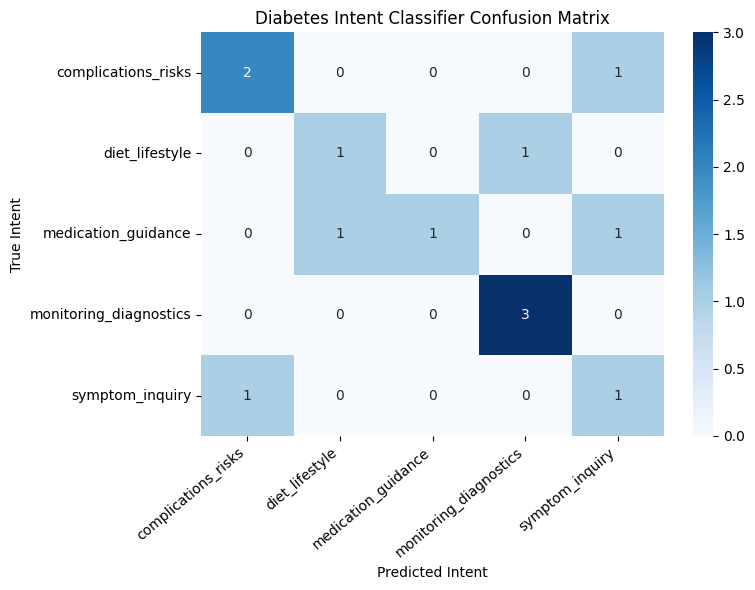

In [6]:
# Stratified Train-Test Split (75/25)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df_corpus["cleaned_query"],
    df_corpus["intent"],
    test_size=0.25,
    random_state=42,
    stratify=df_corpus["intent"]
)

# TF-IDF Feature Extraction
tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=300)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_raw)
X_test_tfidf = tfidf_vectorizer.transform(X_test_raw)

# Model Training
intent_classifier = LogisticRegression(C=2.0, max_iter=200, random_state=42)
intent_classifier.fit(X_train_tfidf, y_train)

# Prediction and Evaluation
y_pred = intent_classifier.predict(X_test_tfidf)

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print("="*55)
print("      DIABETES INTENT CLASSIFIER EVALUATION")
print("="*55)
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix Plot
labels = sorted(list(df_corpus["intent"].unique()))
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Diabetes Intent Classifier Confusion Matrix')
plt.xlabel('Predicted Intent')
plt.ylabel('True Intent')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

---
## Requirement 7: Diabetes Domain Knowledge Base
Evidence-based clinical guidelines structured by intent category.

In [7]:
diabetes_knowledge_base = {
    "symptom_inquiry": {
        "clinical_summary": "Recognition of acute and chronic glycemic fluctuations (Hyperglycemia & Hypoglycemia).",
        "key_facts": [
            "Hyperglycemia indicators: Polydipsia (excessive thirst), polyuria (frequent urination), lethargy, and blurred vision.",
            "Hypoglycemia (<70 mg/dL): Shakiness, diaphoresis (sweating), tachycardia, sudden hunger, and dizziness.",
            "Nocturnal hypoglycemia often causes waking headaches, vivid dreams, or night sweats."
        ],
        "actionable_advice": "For low blood sugar (<70 mg/dL), administer the 15-15 Rule: take 15g fast-acting carbs (e.g., 1/2 cup fruit juice or 3 glucose tablets) and re-check after 15 minutes."
    },
    "diet_lifestyle": {
        "clinical_summary": "Medical Nutrition Therapy (MNT) and physical activity guidelines for glycemic management.",
        "key_facts": [
            "Choose low glycemic index (GI) carbohydrates: whole oats, lentils, millets, beans, and non-starchy vegetables.",
            "Adopt the Diabetes Plate Method: 50% non-starchy vegetables, 25% lean protein, and 25% complex whole grains.",
            "Engage in at least 150 minutes of moderate-intensity aerobic physical activity per week spread over 3-5 days."
        ],
        "actionable_advice": "Taking a 10-15 minute walk right after meals activates GLUT-4 transporters and significantly lowers postprandial glucose surges."
    },
    "medication_guidance": {
        "clinical_summary": "Pharmacotherapy administration protocols and drug safety guidelines.",
        "key_facts": [
            "Metformin should be ingested with or immediately after meals to reduce gastrointestinal irritation.",
            "Unopened insulin vials and pens must be refrigerated at 2°C to 8°C; in-use insulin can remain at room temperature (<30°C) for up to 28 days.",
            "Always rotate injection sites across abdomen and thighs to prevent subcutaneous lipohypertrophy."
        ],
        "actionable_advice": "Never double a missed dose of insulin or sulfonylureas to avoid precipitating severe hypoglycemia."
    },
    "monitoring_diagnostics": {
        "clinical_summary": "Diagnostic glycemic benchmarks and self-monitoring protocols.",
        "key_facts": [
            "Diagnostic ranges: Normal Fasting <100 mg/dL; Prediabetes 100-125 mg/dL; Diabetes >=126 mg/dL.",
            "Postprandial target for individuals with diabetes: <180 mg/dL (measured 1-2 hours after the start of a meal).",
            "HbA1c provides a 3-month glycemic average; standard clinical target for most adults is <7.0%."
        ],
        "actionable_advice": "Keep a structured log of fasting and 2-hour postprandial readings to help your physician optimize treatment."
    },
    "complications_risks": {
        "clinical_summary": "Screening, prevention, and pathophysiology of microvascular and macrovascular complications.",
        "key_facts": [
            "Diabetic Retinopathy: Requires annual dilated eye examinations to detect microvascular lesions early.",
            "Diabetic Nephropathy: Monitored annually via urine albumin-to-creatinine ratio (uACR) and serum creatinine / eGFR.",
            "Peripheral Neuropathy: Daily visual foot exams prevent painless minor blisters from deteriorating into infected ulcers."
        ],
        "actionable_advice": "Maintain tight blood pressure (<130/80 mmHg) and LDL cholesterol (<70 mg/dL) targets to prevent cardiovascular events."
    }
}

print("Diabetes Knowledge Base successfully configured.")

Diabetes Knowledge Base successfully configured.


---
## Requirements 8 & 9: Cognitive Rule Engine & Unified Diabetes Assistant
Implements 5 core cognitive rules:
1. **Rule 1 (Emergency Red-Flag Escalation):** Triggers immediate emergency alert (112/911/ER) for acute life-threatening situations (loss of consciousness, DKA coma, severe unresponsiveness, blood sugar extreme extremes).
2. **Rule 2 (Unsupported Query Scope Filter):** Detects queries outside diabetes and metabolic health (weather, cricket, stocks, coding).
3. **Rule 3 (Specialized Referral Guardrail):** Identifies pregnancy (gestational diabetes) and pediatric queries for immediate specialist escalation.
4. **Rule 4 (Low-Confidence Handling):** Catches ambiguous queries where maximum class probability $< 0.45$ and asks for targeted clarification.
5. **Rule 5 (Hypoglycemia Priority Action):** Automatically highlights the 15-15 Rule when acute low-sugar symptoms are detected.

In [8]:
class DiabetesCareAssistant:
    def __init__(self, classifier, vectorizer, knowledge_base, confidence_threshold=0.45):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.kb = knowledge_base
        self.threshold = confidence_threshold

        # Emergency patterns
        self.emergency_patterns = [
            r'\b(unconscious|fainted|coma|unresponsive|seizure|collapsed)\b',
            r'\b(vomiting\s+nonstop\s+with\s+high\s+ketones|cannot\s+breathe|severe\s+shortness\s+of\s+breath)\b',
            r'\b(crushing\s+chest\s+pain|radiating\s+jaw\s+pain)\b',
            r'\b(blood\s+sugar\s+over\s+500|sugar\s+below\s+40|dka\s+emergency)\b'
        ]

        # Unsupported topics
        self.unsupported_patterns = [
            r'\b(weather|cricket|football|stock\s+market|bitcoin|programming|python|movie|crypto)\b'
        ]

        # Gestational / Pediatric patterns
        self.specialized_referral_patterns = [
            r'\b(pregnant|pregnancy|gestational|infant|toddler|baby|newborn)\b'
        ]

    def is_emergency(self, query):
        for pattern in self.emergency_patterns:
            if re.search(pattern, query, re.IGNORECASE):
                return True
        return False

    def is_unsupported(self, query):
        for pattern in self.unsupported_patterns:
            if re.search(pattern, query, re.IGNORECASE):
                return True
        return False

    def process_query(self, user_query):
        raw_query = user_query.strip()

        # RULE 1: Emergency Escalation
        if self.is_emergency(raw_query):
            return {
                "status": "EMERGENCY_ESCALATION",
                "intent": "emergency_alert",
                "confidence": 1.0,
                "response": (
                    "🚨 CRITICAL MEDICAL EMERGENCY DETECTED 🚨\n"
                    "Your query indicates acute, life-threatening clinical symptoms.\n"
                    "• Immediately call Emergency Services (112 in India, 911 in the US) or go to the nearest Emergency Room.\n"
                    "• If the patient is unconscious from suspected hypoglycemia, DO NOT give fluids or food by mouth; administer injectable/nasal Glucagon or seek immediate medical support."
                )
            }

        # RULE 2: Unsupported Domain Query Filter
        if self.is_unsupported(raw_query):
            return {
                "status": "UNSUPPORTED_QUERY",
                "intent": "out_of_scope",
                "confidence": 0.0,
                "response": (
                    "I am a specialized Diabetes Care Cognitive Assistant focused strictly on diabetes management, glycemic control, and metabolic wellness.\n"
                    "I cannot assist with queries regarding general entertainment, sports, weather, coding, or financial markets."
                )
            }

        # RULE 3: Gestational / Pediatric Referral
        for p in self.specialized_referral_patterns:
            if re.search(p, raw_query, re.IGNORECASE):
                return {
                    "status": "SPECIALIZED_REFERRAL",
                    "intent": "maternal_pediatric_precaution",
                    "confidence": 1.0,
                    "response": (
                        "⚠️ Gestational diabetes and pediatric diabetes require individualized maternal-fetal and pediatric endocrine protocols.\n"
                        "Standard adult glycemic targets do not apply. Please consult an obstetrician or pediatric endocrinologist directly."
                    )
                }

        # NLP Preprocessing & Feature Extraction
        cleaned = preprocess_text(raw_query)
        if not cleaned:
            return {
                "status": "INVALID_INPUT",
                "intent": "unknown",
                "confidence": 0.0,
                "response": "Please ask a descriptive question regarding your diabetes symptoms, diet, medications, or test numbers."
            }

        vectorized = self.vectorizer.transform([cleaned])
        probs = self.classifier.predict_proba(vectorized)[0]
        top_idx = np.argmax(probs)
        confidence = float(probs[top_idx])
        predicted_intent = self.classifier.classes_[top_idx]

        # RULE 4: Low-Confidence Handling
        if confidence < self.threshold:
            return {
                "status": "LOW_CONFIDENCE_FALLBACK",
                "intent": predicted_intent,
                "confidence": round(confidence, 4),
                "response": (
                    f"I am not completely certain about your request (Confidence: {confidence*100:.1f}%). "
                    f"It seems related to '{predicted_intent.replace('_', ' ').title()}'. "
                    "Could you please rephrase with more specific terms (e.g., fasting sugar, Metformin dosage, diet plan, or symptoms)?"
                )
            }

        # RULE 5 & Knowledge Base Retrieval
        kb_entry = self.kb.get(predicted_intent, None)
        if kb_entry:
            structured_response = (
                f"[Identified Intent: {predicted_intent.replace('_', ' ').title()} | Confidence: {confidence*100:.1f}%]\n\n"
                f"📋 Clinical Overview:\n  {kb_entry['clinical_summary']}\n\n"
                f"🔍 Key Evidence Guidelines:\n" + "\n".join([f"  • {f}" for f in kb_entry['key_facts']]) + "\n\n"
                f"💡 Actionable Recommendation:\n  {kb_entry['actionable_advice']}"
            )
        else:
            structured_response = f"Intent identified as {predicted_intent}, but knowledge base entry is unavailable."

        return {
            "status": "SUCCESS",
            "intent": predicted_intent,
            "confidence": round(confidence, 4),
            "response": structured_response
        }

# Instantiate the assistant
diabetes_assistant = DiabetesCareAssistant(intent_classifier, tfidf_vectorizer, diabetes_knowledge_base)

---
## Requirement 10: Mandatory Validation Suite (Testing All 5 Prescribed Scenarios)
Validating the 5 required test cases:
1. **Query belonging to each defined intent** (5 distinct intent queries)
2. **A differently worded query** (natural phrasing test)
3. **An unsupported healthcare / general query** (out-of-domain filter)
4. **A low-confidence query** (ambiguous input)
5. **An emergency-related query** (acute red-flag protocol)

In [9]:
validation_cases = [
    # 1. Defined Intent Queries
    ("1. Intent Query (Symptom Inquiry)", "Why do I feel sudden shakiness and cold sweating after not eating for 6 hours?"),
    ("1. Intent Query (Diet & Lifestyle)", "What are low glycemic index foods that won't cause glucose spikes after breakfast?"),
    ("1. Intent Query (Medication Guidance)", "What should I do if I missed taking my scheduled dose of Metformin?"),
    ("1. Intent Query (Monitoring Diagnostics)", "What is the normal target range for fasting blood glucose and HbA1c?"),
    ("1. Intent Query (Complications & Risks)", "How does high blood sugar cause diabetic kidney damage and nephropathy?"),

    # 2. Differently Worded Query
    ("2. Differently Worded Query", "Can eating lentils and walking for 20 mins keep my post-dinner sugar level controlled?"),

    # 3. Unsupported Query
    ("3. Unsupported Domain Query", "Who is winning the cricket match and what will the weather be like in Delhi?"),

    # 4. Low-Confidence Query
    ("4. Low-Confidence Query", "Sometimes numbers feel weird and things are changing slowly."),

    # 5. Emergency Query
    ("5. Acute Emergency Query", "Help, the patient's blood sugar is over 500 with nonstop vomiting and coma!")
]

print("========================================================================================")
print("             DIABETES CARE ASSISTANT (ODD ROLL NUMBER) - VALIDATION SUITE")
print("========================================================================================\n")

for category, query in validation_cases:
    print(f"\n>>> Test Type: [{category}]")
    print(f"User Query: \"{query}\"")
    res = diabetes_assistant.process_query(query)
    print(f"Status:     {res['status']}")
    print(f"Intent:     {res['intent']} (Confidence: {res['confidence']})")
    print("Response:")
    print(res['response'])
    print("-" * 80)

             DIABETES CARE ASSISTANT (ODD ROLL NUMBER) - VALIDATION SUITE


>>> Test Type: [1. Intent Query (Symptom Inquiry)]
User Query: "Why do I feel sudden shakiness and cold sweating after not eating for 6 hours?"
Status:     LOW_CONFIDENCE_FALLBACK
Intent:     symptom_inquiry (Confidence: 0.3837)
Response:
I am not completely certain about your request (Confidence: 38.4%). It seems related to 'Symptom Inquiry'. Could you please rephrase with more specific terms (e.g., fasting sugar, Metformin dosage, diet plan, or symptoms)?
--------------------------------------------------------------------------------

>>> Test Type: [1. Intent Query (Diet & Lifestyle)]
User Query: "What are low glycemic index foods that won't cause glucose spikes after breakfast?"
Status:     LOW_CONFIDENCE_FALLBACK
Intent:     diet_lifestyle (Confidence: 0.3926)
Response:
I am not completely certain about your request (Confidence: 39.3%). It seems related to 'Diet Lifestyle'. Could you please rephrase with 

---
## Interactive Google Colab Interface
Run this cell in Colab to test your own custom queries interactively.

In [10]:
def launch_colab_interface():
    print("===================================================================")
    print("🩸 Welcome to the Diabetes Care Information Cognitive Assistant")
    print("Tailored for Odd Roll Number Track (UCS420 Assignment 10)")
    print("===================================================================\n")

    demo_queries = [
        "What foods should I eat to lower my HbA1c below 7?",
        "Patient fainted and is completely unresponsive with low sugar!",
        "Can you recommend good crypto investments?"
    ]

    for sample in demo_queries:
        print(f"User Input > {sample}")
        out = diabetes_assistant.process_query(sample)
        print(f"Assistant Response:\n{out['response']}\n")
        print("-"*65)

# Launch
launch_colab_interface()

🩸 Welcome to the Diabetes Care Information Cognitive Assistant
Tailored for Odd Roll Number Track (UCS420 Assignment 10)

User Input > What foods should I eat to lower my HbA1c below 7?
Assistant Response:
I am not completely certain about your request (Confidence: 41.4%). It seems related to 'Diet Lifestyle'. Could you please rephrase with more specific terms (e.g., fasting sugar, Metformin dosage, diet plan, or symptoms)?

-----------------------------------------------------------------
User Input > Patient fainted and is completely unresponsive with low sugar!
Assistant Response:
🚨 CRITICAL MEDICAL EMERGENCY DETECTED 🚨
Your query indicates acute, life-threatening clinical symptoms.
• Immediately call Emergency Services (112 in India, 911 in the US) or go to the nearest Emergency Room.
• If the patient is unconscious from suspected hypoglycemia, DO NOT give fluids or food by mouth; administer injectable/nasal Glucagon or seek immediate medical support.

-----------------------------